In [25]:
import pandas as pd
import joblib
import os
from dotenv import load_dotenv
from conformist import FNRCoP, PredictionDataset, ValidationTrial

In [26]:
OUTPUT_DIR = "/home/mariya/Development/pallas/reports/output/cp/rf_GEX_20260606_190416"
# Create the output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [27]:
# Load the model
RF_MODEL_PATH = "/home/mariya/Data/pallas/models/rf_GEX_20260606_190416/rf_model.joblib"
rf = joblib.load(RF_MODEL_PATH)

In [28]:
# Load test data
X_TEST_CSV_PATH = "/home/mariya/Data/pallas/mlomix_datasets/test-gex/features.gex.csv"
Y_TEST_TSV_PATH = "/home/mariya/Data/pallas/mlomix_datasets/test-gex/labels.csv"
X_test = pd.read_csv(X_TEST_CSV_PATH, index_col=0)
y_test = pd.read_csv(Y_TEST_TSV_PATH, index_col=0, sep="\t").squeeze()
X_test.shape, y_test.shape

((666, 1121), (666, 0))

In [29]:
PREDS_CAL_CSV_PATH = "/home/mariya/Development/pallas/reports/output/predictions/rf_GEX_20260606_190416/cal-gex/cal-gex_predictions.csv"
# Load calibration predictions
preds_cal = pd.read_csv(PREDS_CAL_CSV_PATH, index_col=0)
preds_cal

,true_label,predicted_label,"AML, APL-PML::RARA","AML, CBFA2T3::GLIS2","AML, CBFB::MYH11","AML, CEBPAalt","AML, DEK::NUP214","AML, ETV6-r","AML, FUS::ERG","AML, KAT6A-r",...,"B-ALL, NUTM1-r","B-ALL, PAX5 P80R","B-ALL, PAX5alt","B-ALL, TCF3::PBX1","B-ALL, ZNF384-r","B-ALL, high hyperdiploid","B-ALL, hypodiploid","B-ALL, iAMP21",Non-leukemic,T-ALL
id,,,,,,,,,,,,,,,,,,,,,
SJHBBBM4PX3,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.002879,0.015920,0.015296,0.000329,0.004214,0.003947,0.000000,...,0.004144,0.002882,0.104761,0.014402,0.007580,0.398812,0.078688,0.021828,0.003223,0.028247
SJHBBBN9RDM,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.002225,0.028906,0.006661,0.000000,0.004231,0.000000,0.000000,...,0.000350,0.002574,0.084376,0.006242,0.003626,0.205871,0.050169,0.022101,0.000425,0.048091
817_T,Non-leukemic,Non-leukemic,0.002211,0.000816,0.010066,0.011536,0.000000,0.001957,0.000000,0.000000,...,0.005988,0.015418,0.091809,0.014148,0.013122,0.074932,0.042945,0.017294,0.312856,0.063716
858_T,Non-leukemic,Non-leukemic,0.000379,0.000626,0.011460,0.006613,0.000000,0.001957,0.000000,0.000000,...,0.000284,0.012505,0.086343,0.010093,0.018054,0.061743,0.035041,0.013153,0.345827,0.079644
867_B,Non-leukemic,Non-leukemic,0.000446,0.000111,0.005801,0.009600,0.000000,0.003978,0.001975,0.001960,...,0.002241,0.002734,0.040455,0.017043,0.001688,0.029417,0.024356,0.009618,0.435188,0.026835
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16-328,"B-ALL, DUX4-r","B-ALL, DUX4-r",0.000000,0.000206,0.021329,0.024741,0.000000,0.004160,0.000000,0.001904,...,0.004213,0.000605,0.021508,0.004924,0.003965,0.041773,0.044578,0.005440,0.040131,0.056421
16-335,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000302,0.001288,0.001888,0.000000,0.000000,0.000000,0.000387,...,0.000315,0.000930,0.022216,0.000670,0.005396,0.737348,0.125929,0.026950,0.000494,0.005993
16-338,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000000,0.000000,0.000000,0.000000,0.002000,0.000000,0.000000,...,0.000000,0.000000,0.002019,0.000000,0.000000,0.984834,0.006894,0.000000,0.000000,0.000000


In [30]:
PREDS_TEST_CSV_PATH = "/home/mariya/Development/pallas/reports/output/predictions/rf_GEX_20260606_190416/test-gex/test-gex_predictions.csv"
# Load test predictions
preds_test = pd.read_csv(PREDS_TEST_CSV_PATH, index_col=0)
preds_test

,true_label,predicted_label,"AML, APL-PML::RARA","AML, CBFA2T3::GLIS2","AML, CBFB::MYH11","AML, CEBPAalt","AML, DEK::NUP214","AML, ETV6-r","AML, FUS::ERG","AML, KAT6A-r",...,"B-ALL, NUTM1-r","B-ALL, PAX5 P80R","B-ALL, PAX5alt","B-ALL, TCF3::PBX1","B-ALL, ZNF384-r","B-ALL, high hyperdiploid","B-ALL, hypodiploid","B-ALL, iAMP21",Non-leukemic,T-ALL
id,,,,,,,,,,,,,,,,,,,,,
SJHBBBM5PY5,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.001925,0.001006,0.007351,0.011838,0.000000,0.000000,0.0,0.000000,...,0.002111,0.002565,0.028696,0.003368,0.005558,0.526679,0.079067,0.013470,0.004035,0.023847
SJHBBBM5TXY,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1",0.000000,0.002000,0.004701,0.000074,0.000000,0.000000,0.0,0.002000,...,0.005744,0.000000,0.021450,0.049016,0.005622,0.007544,0.009546,0.008189,0.003911,0.020909
SJHBBBM67H6,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.001925,0.000380,0.012546,0.002704,0.001917,0.000280,0.0,0.000000,...,0.000102,0.005286,0.065009,0.011208,0.018637,0.414571,0.094125,0.023463,0.000220,0.011146
ALLT-330,"B-ALL, ETV6::RUNX1","AML, KMT2A-r",0.000000,0.003974,0.023087,0.020016,0.003663,0.009699,0.0,0.001960,...,0.004086,0.007982,0.087852,0.055906,0.010759,0.046215,0.074759,0.015762,0.004110,0.055928
ALLT-339,"B-ALL, ETV6::RUNX1","B-ALL, high hyperdiploid",0.005555,0.000545,0.009132,0.007901,0.000000,0.000000,0.0,0.000000,...,0.004241,0.004235,0.045029,0.006372,0.006108,0.279260,0.086613,0.032072,0.004385,0.019579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16-270,"B-ALL, ZNF384-r","B-ALL, ZNF384-r",0.000126,0.000423,0.016057,0.010969,0.000000,0.000280,0.0,0.002000,...,0.002250,0.000845,0.018459,0.004531,0.554387,0.034351,0.050944,0.006536,0.006314,0.021626
16-272,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000454,0.000399,0.002902,0.003098,0.000000,0.002000,0.0,0.000000,...,0.000237,0.000179,0.004103,0.002685,0.000984,0.864949,0.037385,0.012723,0.000000,0.002284
16-273,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000224,0.003652,0.003155,0.000146,0.000000,0.0,0.001960,...,0.000102,0.000586,0.025124,0.002172,0.003610,0.728364,0.095497,0.003360,0.004277,0.006987


In [31]:
# # Rename columns for conformist
# cols = {"true_label": "known_class", "predicted_label": "predicted_class"}
# preds_cal = preds_cal.rename(columns=cols)
# preds_test = preds_test.rename(columns=cols)
# preds_cal.head(), preds_test.head()

In [32]:
# PREDS_CAL_CSV_CONFORMIST_PATH = PREDS_CAL_CSV_PATH.replace(".csv", "_conformist.csv")
# PREDS_TEST_CSV_CONFORMIST_PATH = PREDS_TEST_CSV_PATH.replace(".csv", "_conformist.csv")

# # Save the updated predictions to CSV files
# preds_cal.to_csv(PREDS_CAL_CSV_CONFORMIST_PATH)
# preds_test.to_csv(PREDS_TEST_CSV_CONFORMIST_PATH)

In [33]:
# Read in formatted predictions
calpd = PredictionDataset(predictions_csv=PREDS_CAL_CSV_PATH, dataset_name='cal')
testpd = PredictionDataset(predictions_csv=PREDS_TEST_CSV_PATH, dataset_name='test')
calpd, testpd

(<conformist.prediction_dataset.PredictionDataset at 0x729c04dc5330>,
 <conformist.prediction_dataset.PredictionDataset at 0x729c042e3580>)

In [34]:
# First, check for rare classes in the calibration dataset
class_counts = calpd.df['true_label'].value_counts()
print("Class distribution in calibration data:")
print(class_counts)

# Filter out rare classes (optional)
MIN_SAMPLES = 5  # Minimum samples required per class
rare_classes = class_counts[class_counts < MIN_SAMPLES].index.tolist()
if rare_classes:
    print(f"Warning: Found {len(rare_classes)} classes with fewer than {MIN_SAMPLES} samples: {rare_classes}")
    print("These rare classes may cause numerical issues in conformal prediction")

# Modify alpha to be more conservative when working with small datasets
# Smaller alpha -> larger prediction sets -> more conservative
ALPHA = 0.05  # Try a smaller alpha (was 0.1)

mcp = FNRCoP(calpd, alpha=ALPHA)
mcp.calibrate()

# # Try with more regularization
# mcp = FNRCoP(calpd, alpha=ALPHA)

# # Use try/except to handle potential errors
# try:
#     trial = mcp.do_validation_trial(n_runs=10)
#     trial.run_reports(OUTPUT_DIR)
# except ValueError as e:
#     print(f"Error during conformal calibration: {e}")
#     print("Trying with even more conservative settings...")

#     # Try with even smaller alpha as a fallback
#     mcp = FNRCoP(calpd, alpha=0.01)
#     trial = mcp.do_validation_trial(n_runs=5)  # Fewer runs as a fallback
#     trial.run_reports(OUTPUT_DIR)

Class distribution in calibration data:
true_label
B-ALL, high hyperdiploid    84
AML, KMT2A-r                77
B-ALL, ETV6::RUNX1          69
B-ALL, BCR::ABL1-like       58
AML, RUNX1::RUNX1T1         54
AML, NPM1alt                34
B-ALL, KMT2A-r              33
B-ALL, PAX5alt              33
T-ALL                       26
B-ALL, DUX4-r               26
AML, CBFB::MYH11            25
B-ALL, BCR::ABL1            21
B-ALL, hypodiploid          19
B-ALL, TCF3::PBX1           19
AML, CEBPAalt               17
AML, NUP98-r                14
B-ALL, ZNF384-r             12
B-ALL, ETV6::RUNX1-like     10
B-ALL, MEF2D-r               9
B-ALL, iAMP21                8
AML, DEK::NUP214             7
Non-leukemic                 7
AML, APL-PML::RARA           6
AML, CBFA2T3::GLIS2          6
B-ALL, NUTM1-r               5
B-ALL, PAX5 P80R             5
B-ALL, MYC-r                 5
AML, KAT6A-r                 4
B-ALL, HLF-r                 3
AML, ETV6-r                  3
B-ALL, IKZF1 N159Y 

[np.float64(0.05714285723714296), np.float64(0.01428571438428583), np.float64(0.12857142865857152), np.float64(0.05714285723714296), np.float64(0.02857142866857154), np.float64(0.05714285723714296), np.float64(0.05714285723714296), np.float64(0.05714285723714296), np.float64(0.05714285723714296), np.float64(0.07142857152142879), np.float64(0.12857142865857152), np.float64(0.02857142866857154), np.float64(0.10000000009000021), np.float64(0.04285714295285725), np.float64(0.02857142866857154), np.float64(0.04285714295285725), np.float64(0.05714285723714296), np.float64(0.0857142858057145), np.float64(0.0857142858057145), np.float64(0.02857142866857154), np.float64(0.04285714295285725), np.float64(0.04285714295285725), np.float64(0.0857142858057145), np.float64(0.04285714295285725), np.float64(0.04285714295285725), np.float64(0.07142857152142879), np.float64(0.01428571438428583), np.float64(0.02857142866857154), np.float64(0.10000000009000021), np.float64(0.0857142858057145), np.float64(0.

<Figure size 400x300 with 0 Axes>

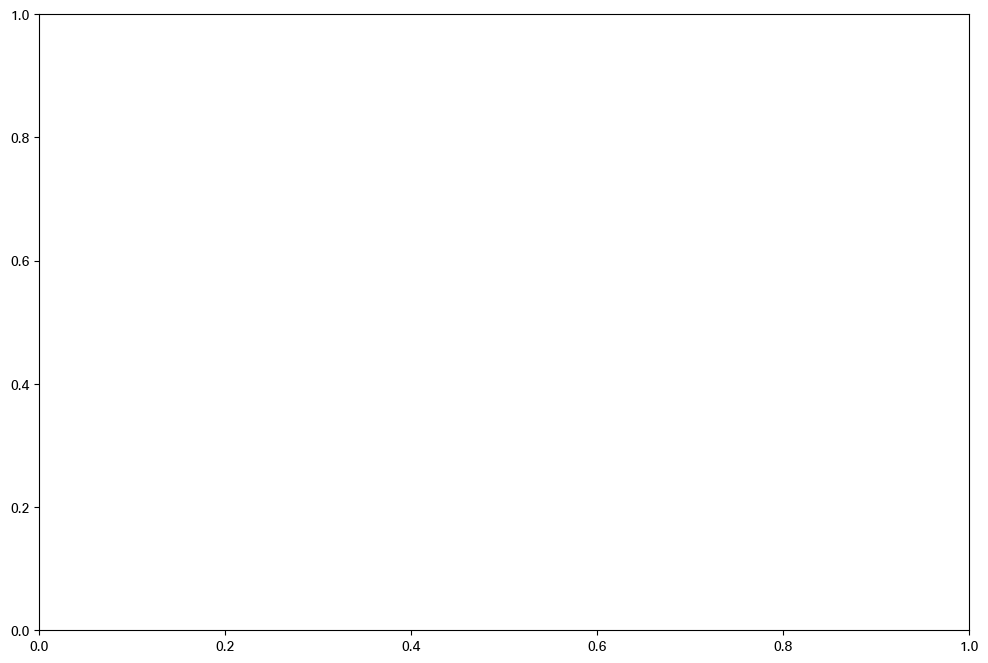

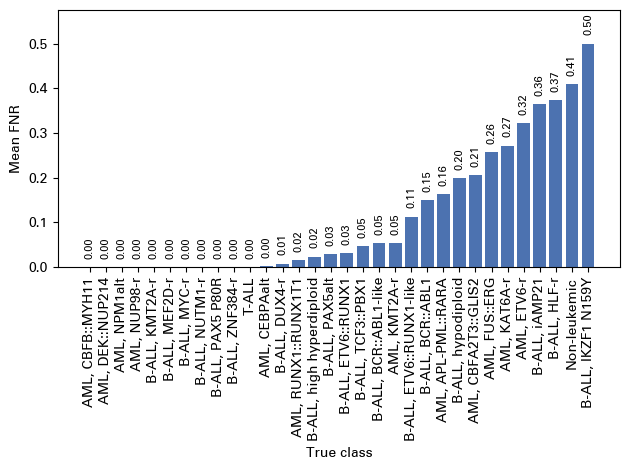

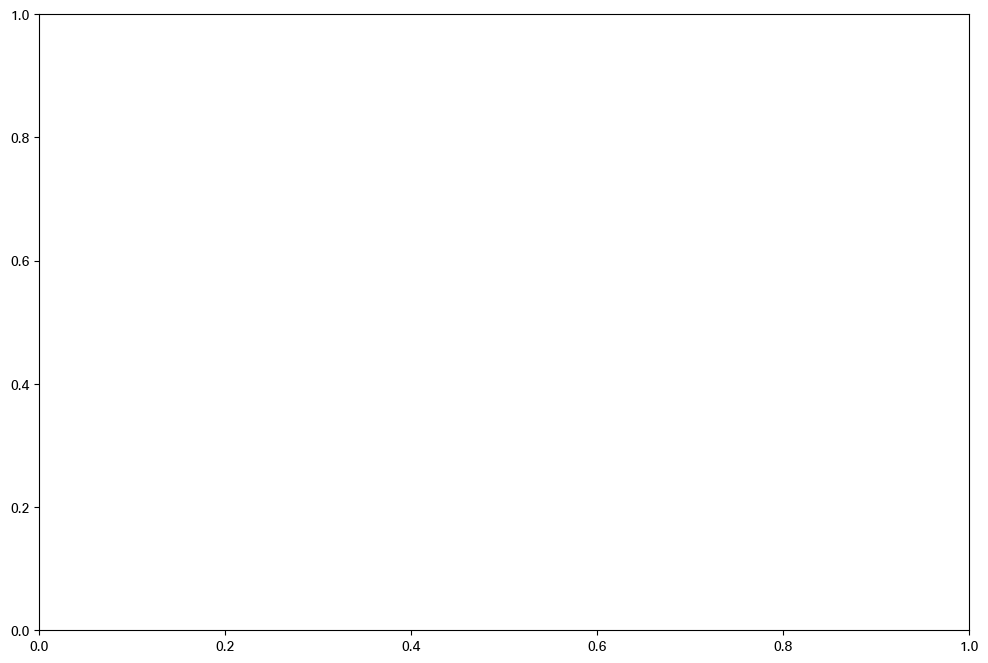

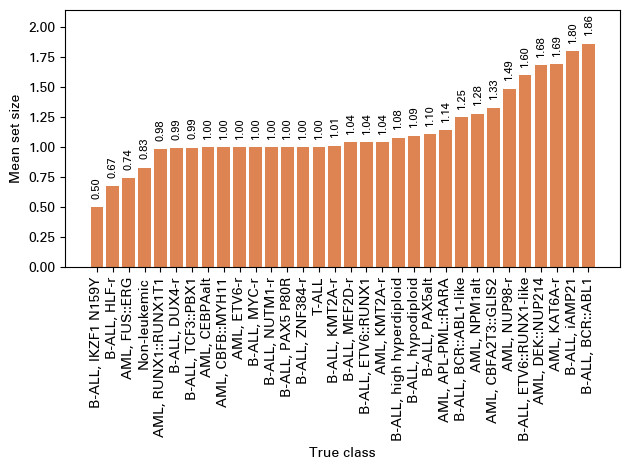

In [35]:
ALPHA=0.05
N_RUNS=1000 # replace with 1000

# Validation trial and reports
mcp = FNRCoP(calpd, alpha=ALPHA)
trial = mcp.do_validation_trial(n_runs=N_RUNS)
trial.run_reports(OUTPUT_DIR)


/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

Saving upset plot to /home/mariya/Development/pallas/reports/output/cp/rf_GEX_20260606_190416/FNRCoP/2026-06-24_19-12-14/upset_plot.pdf


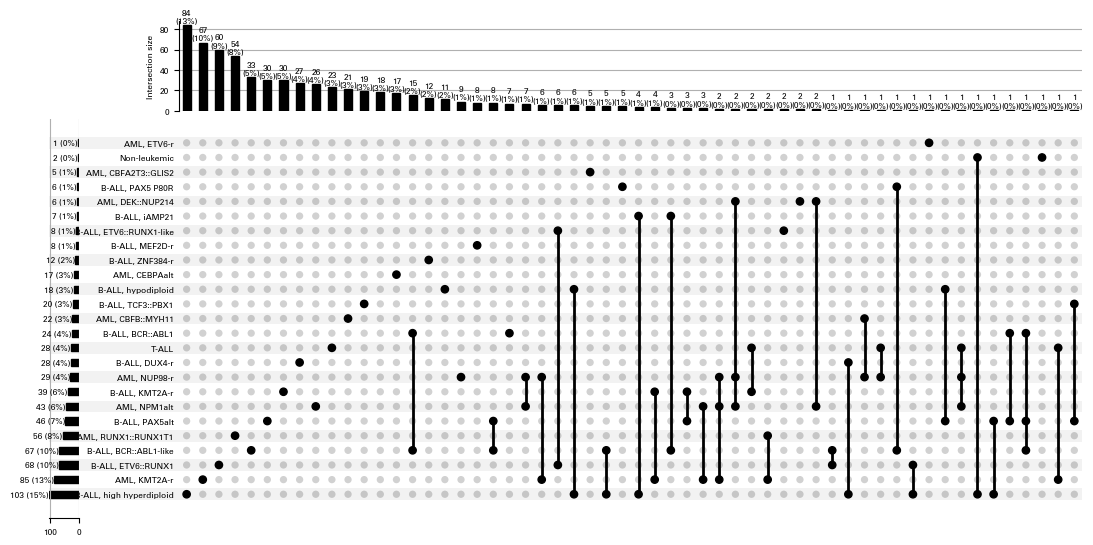

In [36]:
formatted_predictions = mcp.predict(testpd,
                                    OUTPUT_DIR)